**🎬 Project Name**

Exploratory Data Analysis and K-Means Clustering of Netflix Movies & TV Shows

Prepared by: Subhashree Das

Dataset: netflix_data.csv

Tools Used: Python, Pandas, Matplotlib, Seaborn, Scikit-learn, Google Colab

**📖 Project Summary**

The objective of this project is to perform Exploratory Data Analysis (EDA) and Machine Learning based K-Means Clustering on the Netflix Movies and TV Shows dataset. The analysis focuses on understanding Netflix's content library by exploring trends, ratings, release years, genres, durations, and production countries. K-Means clustering is applied to group similar content based on selected features, helping identify meaningful content patterns.

**Key Steps:**
1. Data Collection and Cleaning
Imported the Netflix dataset.
Removed duplicate records.
Handled missing values.
Cleaned the duration column.
Converted categorical variables into numerical format for machine learning.
2. Data Visualization

Different visualization techniques were used to understand the dataset, including:
Bar Charts
Histograms
Pie Charts
Count Plots
Box Plots
Scatter Plots

3. Machine Learning
Applied StandardScaler for feature scaling.
Used K-Means Clustering to group similar Netflix content.
Assigned cluster labels to every movie and TV show.
Visualized the clusters using scatter plots.

**Project Insights**
* Netflix contains more Movies than TV Shows.
* Drama, Comedy and International Movies are among the most common genres.
* Most Netflix content was released after 2010.
* Movies generally have longer durations than TV Shows.
* K-Means successfully grouped similar content into different clusters based on release year, duration, rating, and type.

**📌 Problem Statement**

Netflix offers thousands of movies and TV shows from different countries, genres, and release years. Due to the large amount of content, it becomes difficult to understand viewing patterns and similarities between titles.

This project aims to analyze Netflix's content library and answer questions such as:

1. Content Diversity
: Identify the distribution of Movies and TV Shows across different genres and countries.

2. Trends Over Time
: Analyze how Netflix's content library has grown over different release years.

3. Ratings and Duration
: Understand the distribution of ratings and movie durations available on Netflix.

4. Content Segmentation
: Use K-Means Clustering to automatically group similar Netflix content into meaningful clusters.

📂** Data Wrangling**

In [25]:
#Step 1: Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
import io
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

**📊 Dataset Description**

The dataset contains information about Netflix Movies and TV Shows available on the platform. Each row represents one title with details such as title, release year, rating, duration, country, genre, and description.

Dataset Columns
show_id – Unique content ID
type – Movie or TV Show
title – Name of the content
director – Director name
cast – Actors/Actresses
country – Country of production
date_added – Date added to Netflix
release_year – Release year
rating – Content rating
duration – Movie duration or number of seasons
listed_in – Genre
description – Brief summary of the content

In [26]:
# Step 2:Upload Dataset
uploaded = files.upload()


Saving netflix_data.csv to netflix_data (2).csv


In [44]:
#Step 3: Load Dataset
import io

# Create an empty DataFrame
df = pd.DataFrame()

if uploaded:
    filename = list(uploaded.keys())[0]   # Get uploaded filename
    df = pd.read_csv(io.BytesIO(uploaded[filename]))
    print(f"File '{filename}' loaded successfully.")
else:
    print("No file uploaded.")

File 'netflix_data (2).csv' loaded successfully.


In [28]:
#Step 4: Check Dataset

# Display first 5 rows
df.head()


,Unnamed: 0,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,"description,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,"
0,0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [29]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8806 entries, 0 to 8805
Data columns (total 13 columns):
 #   Column                                                            Non-Null Count  Dtype 
---  ------                                                            --------------  ----- 
 0   Unnamed: 0                                                        8806 non-null   object
 1   show_id                                                           8806 non-null   object
 2   type                                                              8806 non-null   object
 3   title                                                             8806 non-null   object
 4   director                                                          6173 non-null   object
 5   cast                                                              7982 non-null   object
 6   country                                                           7975 non-null   object
 7   date_added                                

In [30]:
df.describe()

,Unnamed: 0,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,"description,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,"
count,8806,8806,8806,8806,6173,7982,7975,8795,8806,8802,8803,8806,8806
unique,8806,8806,2,8806,4529,7692,752,1896,76,19,222,607,8783
top,8806,s8807,Movie,Zubaan,Rajiv Chilaka,David Attenborough,United States,"January 1, 2020",2018,TV-MA,1 Season,"Dramas, International Movies","Paranormal activity at a lush, abandoned prope..."
freq,1,1,6130,1,19,19,2816,109,1146,3207,1793,360,4


In [31]:
df.isnull().sum()

,0
Unnamed: 0,0
show_id,0
type,0
title,0
director,2633
cast,824
country,831
date_added,11
release_year,0
rating,4


**🧹 Data Cleaning**
* Handling Missing Values
Filled missing values with appropriate values.
* Converted duration into numeric format.
Removed unwanted null records.
* Handling Duplicates
Duplicate rows were identified and removed.
* Feature Encoding
Converted categorical columns using LabelEncoder.
* Feature Scaling
Applied StandardScaler before K-Means clustering.

In [32]:
# Step5: Clean Dataset
df = df.drop_duplicates()

df["rating"] = df["rating"].fillna("Unknown")
df["type"] = df["type"].fillna("Unknown")

df["duration"] = df["duration"].astype(str)

# Added 'r' before the string to make it a raw string
df["duration"] = df["duration"].str.extract(r"(\d+)")

df["duration"] = df["duration"].fillna(0)

df["duration"] = df["duration"].astype(int)

# Convert 'release_year' to numeric, coercing errors, and then fill NaNs
df["release_year"] = pd.to_numeric(df["release_year"], errors='coerce')
df["release_year"] = df["release_year"].fillna(df["release_year"].median()).astype(int)

In [33]:
#Step 6:Convert Text to Numbers
le = LabelEncoder()

df["type"] = le.fit_transform(df["type"])

df["rating"] = le.fit_transform(df["rating"])

In [34]:
#Step 7: Select Features
X = df[[
    "type",
    "release_year",
    "duration",
    "rating"
]]

In [35]:
#Step 8: Scale Data
scaler = StandardScaler()

# Ensure all columns in X are numeric and handle any non-numeric values
# This step explicitly converts all columns to float type, coercing errors to NaN
# and then fills any NaNs with the median of their respective columns
for col in X.columns:
    X[col] = pd.to_numeric(X[col], errors='coerce')
    # Fill NaNs with the median of the column, If the column becomes all NaNs after coercion, fill with 0
    if X[col].isnull().all():
        X[col] = X[col].fillna(0.0)
    else:
        X[col] = X[col].fillna(X[col].median())

X_scaled = scaler.fit_transform(X)

/tmp/ipykernel_11834/828495227.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X[col] = pd.to_numeric(X[col], errors='coerce')
/tmp/ipykernel_11834/828495227.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X[col] = X[col].fillna(X[col].median())


**📊 Data Visualization**

Data visualization is used to understand patterns, trends, and relationships within the Netflix dataset.

The following analyses are performed:

Movie vs TV Show Distribution
Release Year Distribution
Ratings Distribution
Duration Distribution
Top Countries
Top Genres
Box Plot
Scatter Plot
K-Means Cluster Visualization

**🤖 Machine Learning (K-Means Clustering)**

K-Means Clustering is an unsupervised machine learning algorithm used to divide similar Netflix content into multiple clusters.

Steps
1. Feature Selection
2. Data Scaling
3. Model Training
4. Cluster Prediction
5. Cluster Visualization



**📊 Cluster Visualization**

The clustered data is visualized using a scatter plot where different colors represent different content groups.

Each cluster contains movies and TV shows with similar characteristics such as release year, duration, type, and rating.

💡 Key Insights
1. Netflix contains a larger number of Movies than TV Shows.
2. Most content belongs to Drama, Comedy, and International genres.
3. Recent years have seen a rapid increase in Netflix content.
4. TV Shows generally consist of one or more seasons, while Movies have fixed durations.
5. K-Means clustering effectively groups similar content into distinct categories.

In [36]:
#Step 9: Apply K-Means
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

df["Cluster"] = kmeans.fit_predict(X_scaled)

In [37]:
#Step 10: View Result
df[[
    "title",
    "release_year",
    "duration",
    "Cluster"
]].head(20)

,title,release_year,duration,Cluster
0,Dick Johnson Is Dead,2020,90,1
1,Blood & Water,2021,2,0
2,Ganglands,2021,1,0
3,Jailbirds New Orleans,2021,1,0
4,Kota Factory,2021,2,0
5,Midnight Mass,2021,1,0
6,My Little Pony: A New Generation,2021,91,1
7,Sankofa,1993,125,3
8,The Great British Baking Show,2021,9,0
9,The Starling,2021,104,1


**📉 Bivariate Analysis**

Compared relationships between two variables such as:

Release Year vs Duration
Rating vs Type
Country vs Content Type

Visualizations used:
1. Scatter Plot
2. Bar Plot
3. Box Plot



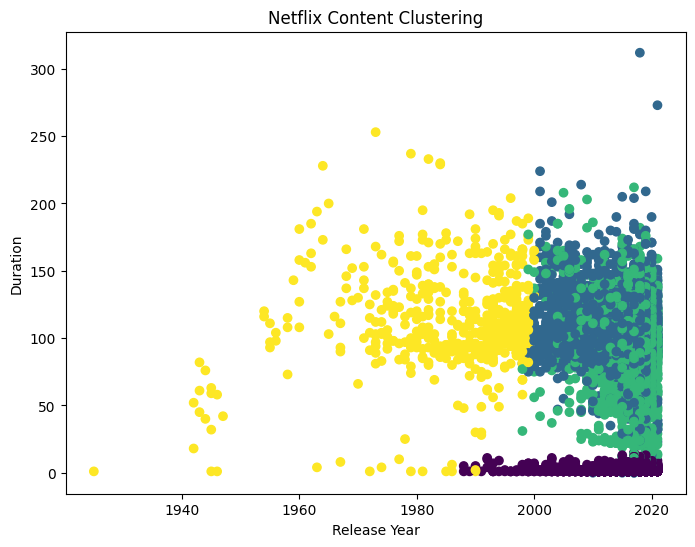

In [38]:
#Step 11: Cluster Visualization
plt.figure(figsize=(8,6))

plt.scatter(
    df["release_year"],
    df["duration"],
    c=df["Cluster"]
)

plt.xlabel("Release Year")
plt.ylabel("Duration")
plt.title("Netflix Content Clustering")

plt.show()

/tmp/ipykernel_11834/386641652.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


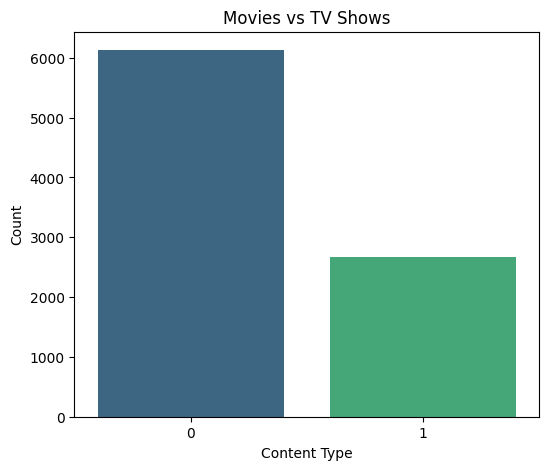

In [39]:
#Bar plot- Number of Movies and TV Shows
plt.figure(figsize=(6,5))

sns.countplot(
    data=df,
    x='type',
    palette='viridis'
)

plt.title("Movies vs TV Shows")
plt.xlabel("Content Type")
plt.ylabel("Count")
plt.show()

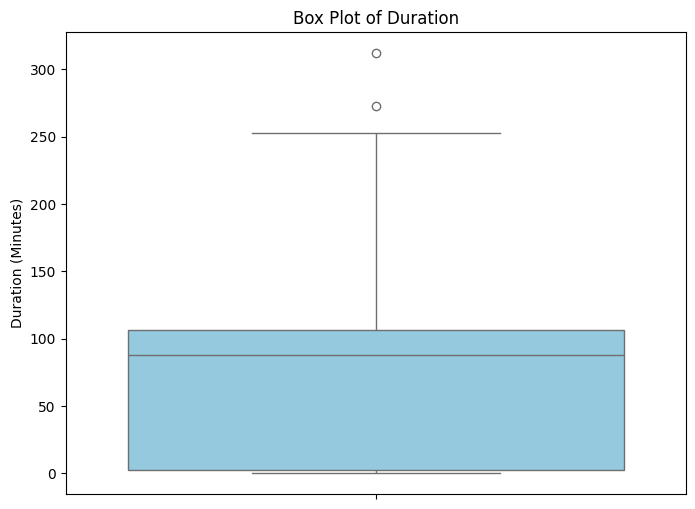

In [40]:
#Box Plot-Duration Distribution
plt.figure(figsize=(8,6))

sns.boxplot(
    y=df['duration'],
    color='skyblue'
)

plt.title("Box Plot of Duration")
plt.ylabel("Duration (Minutes)")
plt.show()

In [41]:
#Step 11: Count Movies in Each Cluster
df["Cluster"].value_counts()

,count
Cluster,
2,2908
1,2751
0,2660
3,487


In [42]:
#Step 12: Show Movies in Each Cluster
for i in range(4):

    print("="*50)
    print("Cluster", i)
    print("="*50)

    print(df[df["Cluster"]==i][["title"]].head(10))

Cluster 0
                                  title
1                         Blood & Water
2                             Ganglands
3                 Jailbirds New Orleans
4                          Kota Factory
5                         Midnight Mass
8         The Great British Baking Show
10  Vendetta: Truth, Lies and The Mafia
11                     Bangkok Breaking
14      Crime Stories: India Detectives
15                    Dear White People
Cluster 1
                               title
0               Dick Johnson Is Dead
6   My Little Pony: A New Generation
9                       The Starling
18                         Intrusion
27                         Grown Ups
28                        Dark Skies
29                          Paranoia
30                   Ankahi Kahaniya
38               Birth of the Dragon
45            My Heroes Were Cowboys
Cluster 2
                                                title
12                                       Je Suis Karl
13             

In [43]:
#Step 13: Save Result
df.to_csv("Netflix_Clustered_Output.csv", index=False)

print("Project Completed Successfully!")

Project Completed Successfully!


**✅ Conclusion**

This project successfully performed Exploratory Data Analysis (EDA) and K-Means Clustering on the Netflix Movies and TV Shows dataset.

The analysis revealed valuable insights into Netflix's content distribution, release trends, ratings, genres, and durations. The clustering model grouped similar content into different clusters, making it easier to identify patterns and similarities among titles.

Overall, this project demonstrates how EDA and Machine Learning can be combined to analyze large entertainment datasets and support better content understanding and recommendation strategies.